# Data Quality Assesment

This notebook should be used once in the project to assess the quality of the dataset we are working with. The results, together with any relevant configurations, will be saved to the WandB project.

> # ⚠ Warning
> This script has been run.
> leakage probabilities have been checked manually and actual
> doublegangers has been moved from  
> .../test_img/ to .../test_img_duplicate/
> # ⚠ Warning




## Notebook Setup

### pip installs

In [87]:
!pip install uv
!uv pip install --system -q wandb



!uv pip install --system git+https://github.com/JESvane99/DLVR_group15.git

Using Python 3.13.15 environment at: /usr
Resolved 170 packages in 1.19s
Checked 170 packages in 2ms


### Imports

In [88]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import wandb
from PIL import Image
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.models import ResNet18_Weights, resnet18
from google.colab import userdata


from dlvr.simple_crack_dataset import SimpleCrackDataset


### Helper methods


In [89]:
def log_figure_to_wandb(fig, run: wandb.Run, save_name: str, caption: str | None = None):
    """
    Log a matplotlib figure to Weights & Biases.
    """
    run.log({save_name: wandb.Image(fig, caption=caption)})
    plt.close(fig)  # Close the figure to free memory

def mount_drive():
    cwd = Path.cwd()
    print(cwd.absolute())
    if not (cwd / 'drive').exists():
        from google.colab import drive
        drive.mount('/content/drive')
    else:
        print("Drive already mounted.")
        print("drive contains:")
        print(*list((cwd / 'drive').glob('*')), sep='\n')
    return cwd / 'drive'

def dataset_path():
    """
    Return the path to the dataset directory.
    """
    dp = mount_drive() / 'MyDrive' / 'Colab_Shared_Datasets' / 'deepcrack_dataset'

    if not dp.exists():
        raise FileNotFoundError(f"Dataset path {dp} does not exist. Please check the path.")
    print(f"Dataset path: {dp}")
    print("Contents of the dataset directory:")
    print(*list(dp.glob('*')), sep='\n')
    return dp


## Assessment Methods

### Visual Inspection

In [90]:
def visualise_samples(dataset, n=4, mean: list | None = None, std: list | None = None, run : wandb.Run | None = None):
    """
    Show n examples with proper denormalization.
    """
    mean = mean if mean is not None else [0, 0, 0]
    std = std if std is not None else [1, 1, 1]

    fig, axes = plt.subplots(n, 2, figsize=(12, n * 5))
    for i in range(n):
        indx = np.random.randint(0, len(dataset))
        img_tensor, mask_tensor = dataset[indx]

        # Denormalize image: class-wise (img * std) + mean
        img = img_tensor.clone()
        for c in range(3):
            img[c] = img[c] * std[c] + mean[c]

        img = torch.clamp(img, 0, 1).permute(1, 2, 0).numpy()
        mask = mask_tensor.permute(1, 2, 0).squeeze().numpy()

        ax_img = axes[i][0] if n > 1 else axes[0]
        ax_mask = axes[i][1] if n > 1 else axes[1]

        ax_img.imshow(img)
        ax_img.set_title("Denormalized Input Image")
        ax_img.axis("off")

        ax_mask.imshow(mask, cmap="gray")
        ax_mask.set_title("Ground Truth Mask")
        ax_mask.axis("off")

    plt.suptitle("Images and corresponding ground truth masks", fontsize=14)
    plt.tight_layout()

    plt.show()
    return fig


### Mask/Label imbalance

In [91]:
def label_proportion(mask: torch.Tensor):
    """
    Calculate the proportion of true pixels in a binary mask.
    """
    n_pixels = mask.nelement()
    n_true = mask.sum().item()  # Count of true pixels
    return n_true / n_pixels

def mean_label_proportion(dataloader):
    """
    Calculate the mean proportion of true pixels across all masks in the dataloader.
    """
    label_prop = []

    for _, masks in dataloader:
        label_prop.append(label_proportion(masks))
    mean_label_proportion = sum(label_prop) / len(label_prop)
    return mean_label_proportion, label_prop

### Image size distribution

In [92]:
def check_image_sizes(image_dir, sample_size=None):
    """
    Check the distribution of original image sizes before resizing.
    Extreme size variation can indicate mixed data sources or quality issues.
    """
    widths, heights = [], []
    image_files = list(Path(image_dir).rglob('*.jpg')) + \
                  list(Path(image_dir).rglob('*.png')) + \
                  list(Path(image_dir).rglob('*.jpeg'))

    # Sample a subset for speed
    import random
    if not sample_size is None:
        sampled = random.sample(image_files, min(sample_size, len(image_files)))
    else:
        sampled = image_files  # Use all images if no sample size is specified
        print(f"Using all {len(sampled)} images for analysis.")
    for path in sampled:
        try:
            with Image.open(path) as img:
                w, h = img.size
                widths.append(w)
                heights.append(h)
        except Exception:
            print(f"something went wrong when opening {path}")
            print(f"!!! CHECK FOR CORRUPT DATA !!!")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].hist(widths,  bins=20, color='steelblue', edgecolor='white')
    axes[0].set_title('Image widths'); axes[0].set_xlabel('Pixels')

    axes[1].hist(heights, bins=20, color='coral',     edgecolor='white')
    axes[1].set_title('Image heights'); axes[1].set_xlabel('Pixels')

    plt.suptitle(f'Image size distribution (sample of {len(widths)})', fontsize=12)
    plt.tight_layout()
    plt.show()

    print(f'Width:  min={min(widths)}, max={max(widths)}, median={int(np.median(widths))}')
    print(f'Height: min={min(heights)}, max={max(heights)}, median={int(np.median(heights))}')

    if max(widths) / max(min(widths), 1) > 10:
        print('WARNING: Very large variation in image sizes — check for outliers.')
    return (max(widths), min(widths)), (max(heights), min(heights)), fig

### Data Leakage

In [93]:
def find_train_val_duplicates(train_dataset, val_dataset, threshold=0.95, batch_size=32):
    """
    Find likely duplicate images across training and validation datasets.

    Why? A validation image that also appears in the training set makes
    validation accuracy misleading.

    How? A pretrained ResNet-18 extracts one feature vector per image. Pairs
    with cosine similarity at or above `threshold` are returned for manual
    review. A high threshold is intentionally used because similar is not
    necessarily identical: augmentation, compression, or resizing can change
    pixel values.

    Note that this is just one type of train/val data leakage — there are many
    other ways to leak information. For example, if the validation set contains
    images of the same objects (e.g., patients) as the training set, the model
    may perform well on validation but fail to generalize to new objects.
    """

    def dataset_paths(dataset):
        if hasattr(dataset, 'pairs'):
            return [path for path, _ in dataset.pairs]
        if hasattr(dataset, 'samples'):
            return [path for path, _ in dataset.samples]
        if hasattr(dataset, 'imgs'):
            return [path for path, _ in dataset.imgs]
        raise TypeError("Expected an ImageFolder-style dataset with `.samples` or `.imgs`.")

    train_paths = dataset_paths(train_dataset)
    val_paths = dataset_paths(val_dataset)
    train_dataset.transform = transforms.Compose([
        transforms.Resize((256,256)),
        transforms.ToTensor(),
    ])

    train_dataset.target_transform = transforms.Compose([
        transforms.Resize((256,256)),
        transforms.ToTensor(),
    ])

    val_dataset.transform = transforms.Compose([
        transforms.Resize((256,256)),
        transforms.ToTensor(),
    ])

    val_dataset.target_transform = transforms.Compose([
        transforms.Resize((256,256)),
        transforms.ToTensor(),
    ])


    weights = ResNet18_Weights.DEFAULT
    model = resnet18(weights=weights)
    model.fc = torch.nn.Identity()
    model = model.to(DEVICE).eval()

    def extract_features(dataset):
        loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
        features = []
        with torch.inference_mode():
            for images, _ in loader:
                batch_features = model(images.to(DEVICE))
                features.append(F.normalize(batch_features, p=2, dim=1).cpu())
        return torch.cat(features)

    train_features = extract_features(train_dataset)
    val_features = extract_features(val_dataset)
    similarity = val_features @ train_features.T
    val_indices, train_indices = torch.where(similarity >= threshold)

    pairs = []
    for val_index, train_index in zip(val_indices.tolist(), train_indices.tolist()):
        pairs.append({
            'train_path': train_paths[train_index],
            'val_path': val_paths[val_index],
            'similarity': float(similarity[val_index, train_index]),
        })

    pairs.sort(key=lambda pair: pair['similarity'], reverse=True)
    print(f'Found {len(pairs)} possible train/validation duplicate pair(s).')
    for pair in pairs[:10]:
        print(f"{pair['similarity']:.3f}  train: {pair['train_path']}  val: {pair['val_path']}")
    return pairs


### Data Corruption

In [94]:
def find_corrupt_images(image_dir):
    """
    Scan for images that cannot be opened.
    Corrupt images will crash training with cryptic errors.
    Run this once before you start training.
    """
    image_files = list(Path(image_dir).rglob('*.jpg')) + \
                  list(Path(image_dir).rglob('*.png')) + \
                  list(Path(image_dir).rglob('*.jpeg'))
    corrupt = []
    for path in image_files:
        try:
            with Image.open(path) as img:
                img.verify()
        except Exception as e:
            corrupt.append((path, str(e)))

    if corrupt:
        print(f'Found {len(corrupt)} corrupt image(s):')
        for path, err in corrupt:
            print(f'  {path}: {err}')
    else:
        print(f'Scanned {len(image_files)} images — no corrupt files found.')
    return corrupt



## configurations

### WandB config

In [95]:

WANDB_ENTITY = "DLVR-group-15"
WANDB_PROJECT = "U_net_Crack_Segmentation"
WANDB_NAME = "data_assessment"

### Data assessment config

In [96]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATAPATH = dataset_path()  # Mount Google Drive and get the dataset path
print(DEVICE)

/content
Drive already mounted.
drive contains:
/content/drive/MyDrive
/content/drive/.shortcut-targets-by-id
/content/drive/.Trash-0
/content/drive/.Encrypted
Dataset path: /content/drive/MyDrive/Colab_Shared_Datasets/deepcrack_dataset
Contents of the dataset directory:
/content/drive/MyDrive/Colab_Shared_Datasets/deepcrack_dataset/test_img
/content/drive/MyDrive/Colab_Shared_Datasets/deepcrack_dataset/test_lab
/content/drive/MyDrive/Colab_Shared_Datasets/deepcrack_dataset/README.md
/content/drive/MyDrive/Colab_Shared_Datasets/deepcrack_dataset/train_lab
/content/drive/MyDrive/Colab_Shared_Datasets/deepcrack_dataset/train_img
cuda


## WandB login

In [97]:
# Retrieve API key from Colab Secrets
wandb_key = userdata.get('WANDB-API-KEY')
wandb.login(key=wandb_key)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.forge.coreweave.com.
wandb: Appending key for api.forge.coreweave.com to your netrc file: /root/.netrc


True

## Run!

Scanned 1074 images — no corrupt files found.
Using all 1074 images for analysis.


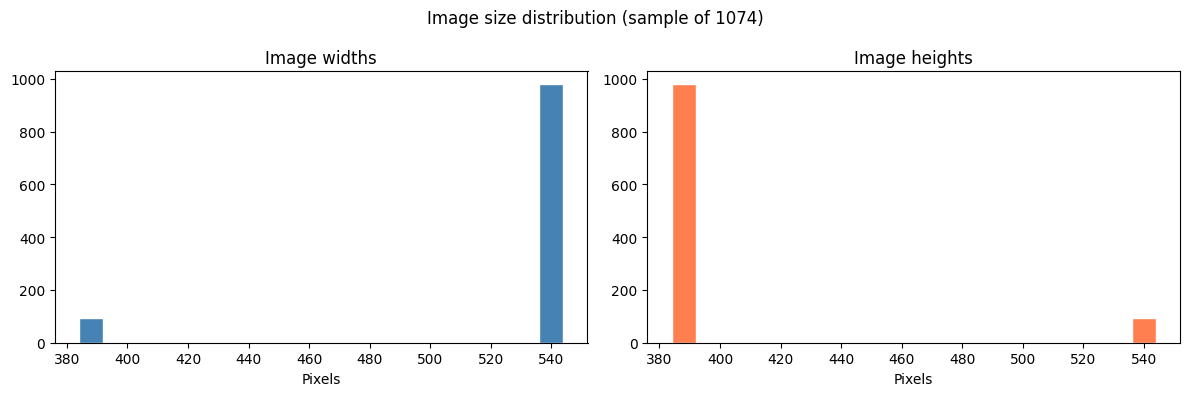

Width:  min=384, max=544, median=544
Height: min=384, max=544, median=384


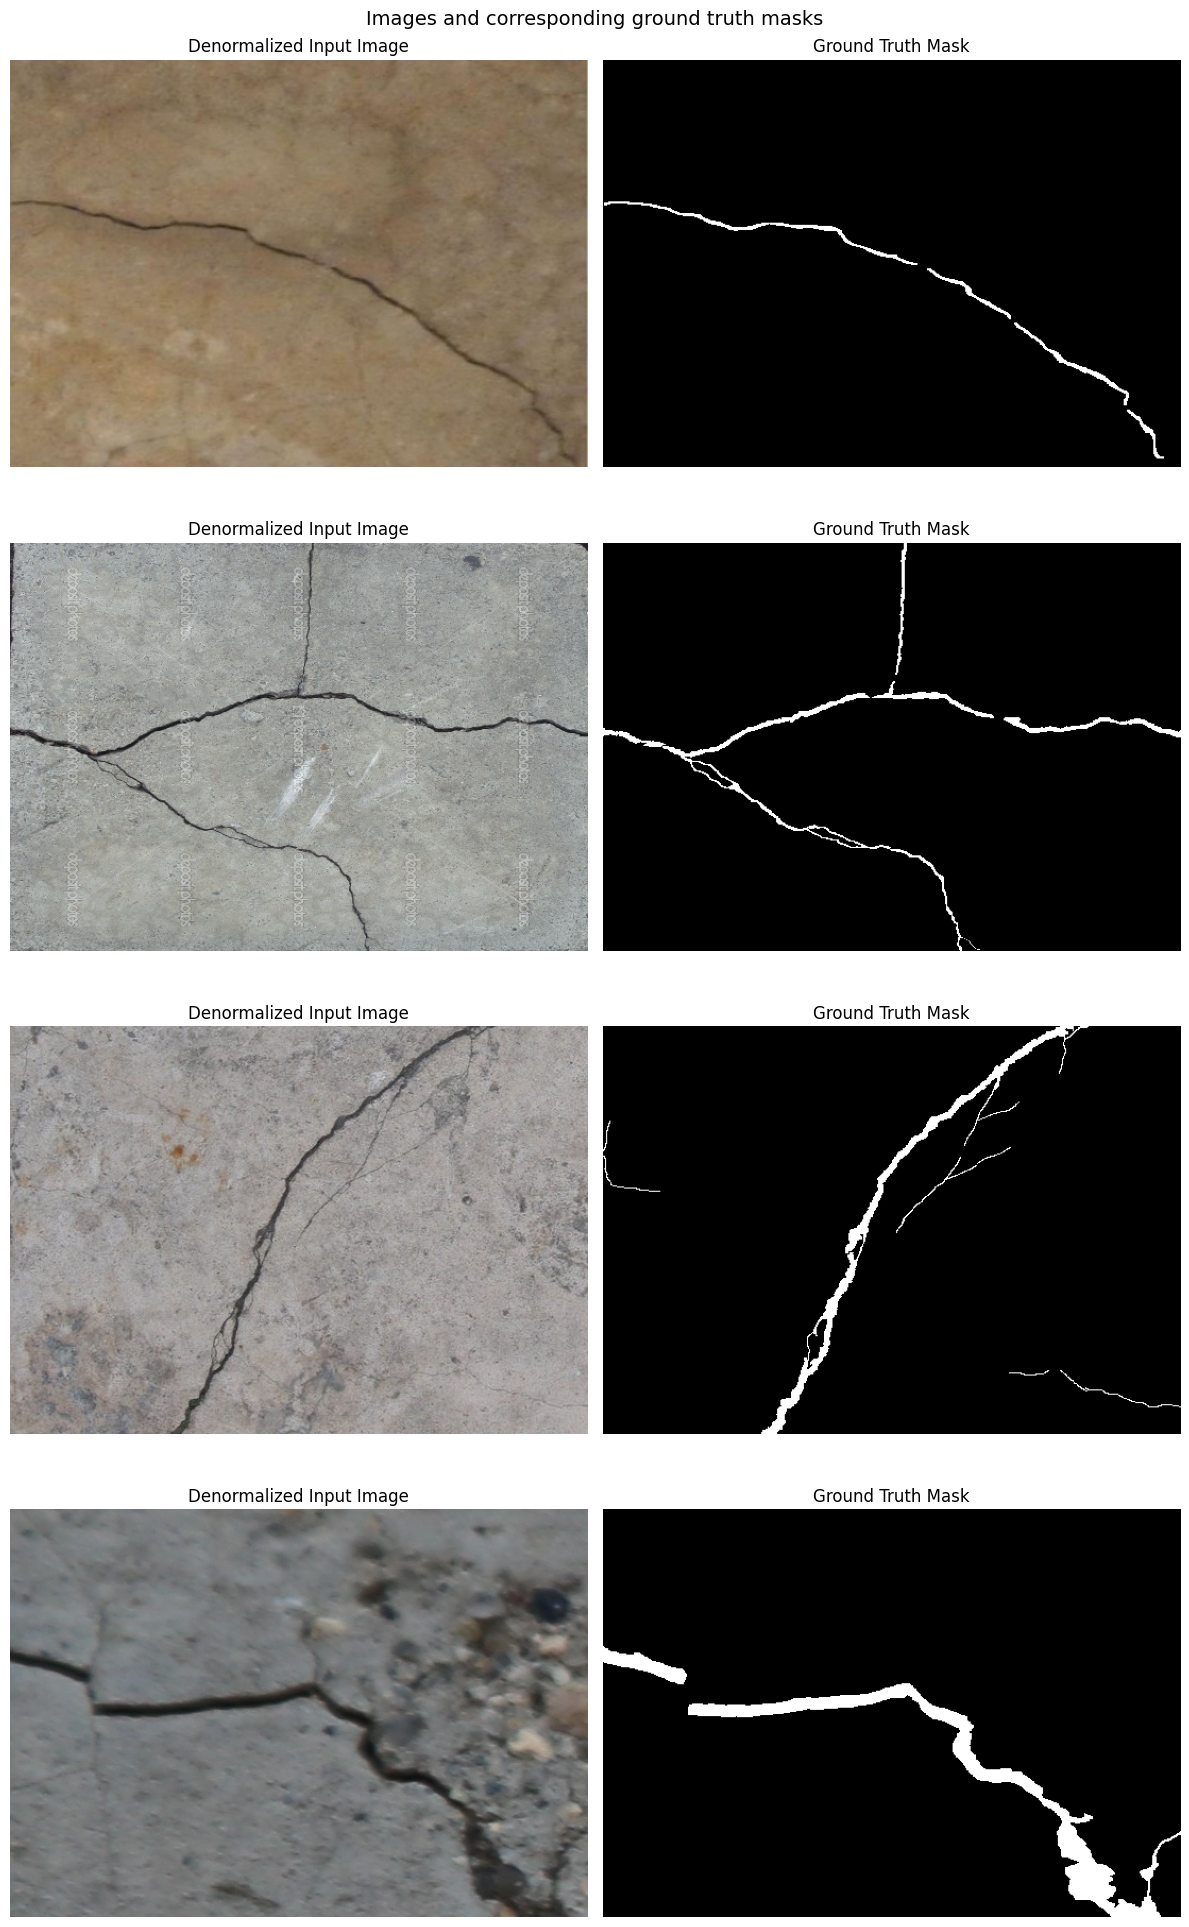

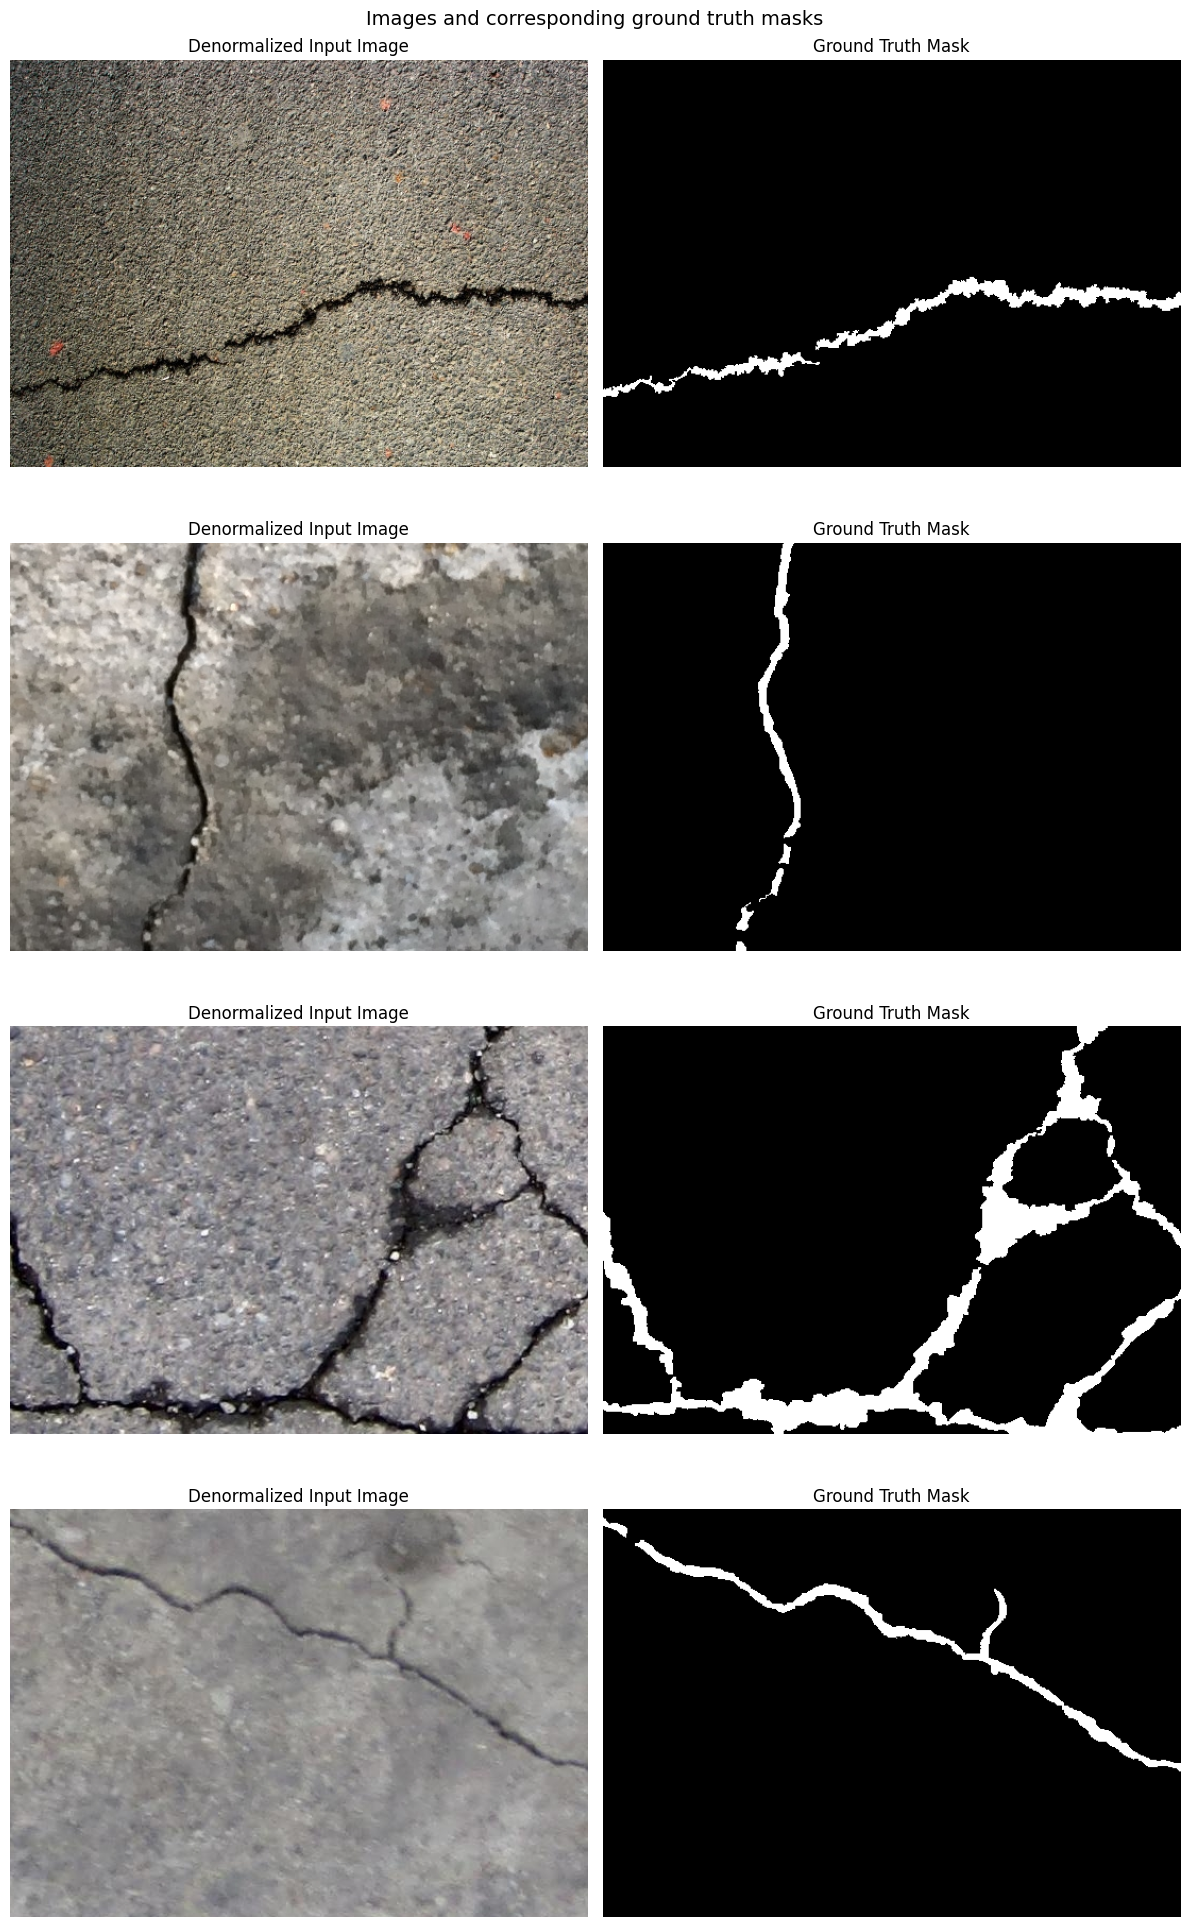

Found 44 possible train/validation duplicate pair(s).
0.998  train: /content/drive/MyDrive/Colab_Shared_Datasets/deepcrack_dataset/train_img/11158.jpg  val: /content/drive/MyDrive/Colab_Shared_Datasets/deepcrack_dataset/test_img/11216.jpg
0.988  train: /content/drive/MyDrive/Colab_Shared_Datasets/deepcrack_dataset/train_img/11289-10.jpg  val: /content/drive/MyDrive/Colab_Shared_Datasets/deepcrack_dataset/test_img/11289-10.jpg
0.987  train: /content/drive/MyDrive/Colab_Shared_Datasets/deepcrack_dataset/train_img/11289-9.jpg  val: /content/drive/MyDrive/Colab_Shared_Datasets/deepcrack_dataset/test_img/11289-9.jpg
0.983  train: /content/drive/MyDrive/Colab_Shared_Datasets/deepcrack_dataset/train_img/11289-7.jpg  val: /content/drive/MyDrive/Colab_Shared_Datasets/deepcrack_dataset/test_img/11289-7.jpg
0.982  train: /content/drive/MyDrive/Colab_Shared_Datasets/deepcrack_dataset/train_img/11187-5.jpg  val: /content/drive/MyDrive/Colab_Shared_Datasets/deepcrack_dataset/test_img/11236-5.jpg
0.9

mean_test_label_proportion,▁
mean_train_label_proportion,▁
mean_test_label_proportion,0.04336
mean_train_label_proportion,0.02825


In [98]:
with wandb.init(
    entity=WANDB_ENTITY,
    project=WANDB_PROJECT,
    name=WANDB_NAME,
    config={
        "device": str(DEVICE),
        "data_content": str(DATAPATH),
    },
    notes="data assessment"
) as run:
    transform = transforms.Compose([
        transforms.ToTensor(),
    ])


    train_dataset = SimpleCrackDataset(root=DATAPATH,
                                transform=transform,
                                target_transform=transform,
                                mode='train')
    test_dataset = SimpleCrackDataset(root=DATAPATH,
                                transform=transform,
                                target_transform=transform,
                                mode='test')


    corrupt = find_corrupt_images(DATAPATH)

    run.log({"corrupt_images": corrupt})

    widths, heights, size_fig = check_image_sizes(DATAPATH, sample_size=None)

    log_figure_to_wandb(size_fig, run, "image_size_distribution", caption="Distribution of image sizes in the dataset.")
    train_vis_fig = visualise_samples(train_dataset)
    test_vis_fig = visualise_samples(test_dataset)

    log_figure_to_wandb(train_vis_fig, run, "train_samples", caption="Randomly selected training samples with corresponding ground truth masks.")
    log_figure_to_wandb(test_vis_fig, run, "test_samples", caption="Randomly selected test samples with corresponding ground truth masks.")
    train_test_duplicates = find_train_val_duplicates(train_dataset=train_dataset, val_dataset=test_dataset)

    run.log({"data-leakage": train_test_duplicates})
    mean_train_label_prop, train_label_props = mean_label_proportion(DataLoader(train_dataset, batch_size=32))
    mean_test_label_prop, test_label_props = mean_label_proportion(DataLoader(test_dataset, batch_size=32))

    run.log({
        "mean_train_label_proportion": mean_train_label_prop,
        "train_label_proportions": train_label_props,
        "mean_test_label_proportion": mean_test_label_prop,
        "test_label_proportions": test_label_props,
    })